<a href="https://colab.research.google.com/github/SaharaAli16/UNT_Teaching/blob/main/DTSC_4050/Project/DTSC4050_Carseats_Project_Demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DTSC 4050 — Solved Mini-Project: Predicting Car Seat Sales
**ISLP Carseats dataset | Regression + statistical inference**

**Learning goal:** Work through the same eight sections used in the final project rubric. Run cells from top to bottom in **Google Colab** (internet needed once to install ISLP and download its dataset). The notebook computes and explains findings rather than assuming results.

**Dataset source:** [ISLP Carseats documentation](https://islp.readthedocs.io/en/latest/datasets/Carseats.html). The dataset contains 400 stores; `Sales` is unit sales in thousands. This is a teaching dataset, not a live sales forecast.


## 1. Problem definition and research questions
A retailer wants to understand differences in car seat sales across stores and estimate sales from store and market characteristics.

1. **Descriptive:** How do sales vary with price and advertising?
2. **Inferential:** Do stores in urban and non-urban locations have different mean sales?
3. **Predictive:** Does multiple linear regression or a regression tree better predict sales at unseen stores?

**Target:** `Sales` (numeric, thousands of units). **Task:** supervised regression. **Predictors:** `CompPrice`, `Income`, `Advertising`, `Population`, `Price`, `ShelveLoc`, `Age`, `Education`, `Urban`, `US`. We exclude the target from the predictors.


## 2. Load data, inspect, and clean
We first inspect the dataset; we do not automatically delete observations or assume all unusual values are errors. Missing predictor values, if any, will be imputed **inside a training-only pipeline** to avoid leakage.

In [14]:
# In Google Colab, run this cell once. In a local environment, install ISLP first.
%pip -q install ISLP

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ISLP import load_data
from scipy import stats
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
pd.set_option('display.max_columns', 30)
df = load_data('Carseats').copy()
print('Shape:', df.shape)
display(df.head())
print('Column types:')
print(df.dtypes)


Shape: (400, 11)


,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


Column types:
Sales           float64
CompPrice         int64
Income            int64
Advertising       int64
Population        int64
Price             int64
ShelveLoc      category
Age               int64
Education         int64
Urban          category
US             category
dtype: object


In [16]:
print('Missing values by column:')
display(df.isna().sum().to_frame('missing_count'))
print('Exact duplicate rows:', df.duplicated().sum())
print('Sales range:', df['Sales'].min(), 'to', df['Sales'].max())
print('Categorical levels:')
for c in df.select_dtypes(include=['object', 'category']).columns:
    print(c, df[c].value_counts(dropna=False).to_dict())

# A duplicated feature row might represent two stores, so do not blindly remove duplicates.
# A missing target cannot be used for supervised learning.
before = len(df)
df = df.dropna(subset=['Sales']).copy()
print(f'Removed {before-len(df)} rows with missing target.')
assert df['Sales'].notna().all()


Missing values by column:


,missing_count
Sales,0
CompPrice,0
Income,0
Advertising,0
Population,0
Price,0
ShelveLoc,0
Age,0
Education,0
Urban,0


Exact duplicate rows: 0
Sales range: 0.0 to 16.27
Categorical levels:
ShelveLoc {'Medium': 219, 'Bad': 96, 'Good': 85}
Urban {'Yes': 282, 'No': 118}
US {'Yes': 258, 'No': 142}
Removed 0 rows with missing target.


**Cleaning decision:** Retain plausible extreme sales values; investigate rather than automatically remove them. We preserve possible repeated store profiles because there is no unique store identifier. The preprocessing pipelines below handle any missing predictor values using training data only.

**Discussion:** Why is filling missing values using the entire dataset before splitting potentially problematic?

## 3. Exploratory data analysis
We summarize quantitative variables and produce **four** meaningful plots. Each chart should support a sentence about the data, not just be included for decoration.

In [17]:
display(df.describe(include='number').T.round(2))
print('Sales median:', round(df['Sales'].median(), 2))
print('Sales standard deviation:', round(df['Sales'].std(), 2))


,count,mean,std,min,25%,50%,75%,max
Sales,400.0,7.50,2.82,0.0,5.39,7.49,9.32,16.27
CompPrice,400.0,124.98,15.33,77.0,115.00,125.00,135.00,175.00
Income,400.0,68.66,27.99,21.0,42.75,69.00,91.00,120.00
Advertising,400.0,6.64,6.65,0.0,0.00,5.00,12.00,29.00
Population,400.0,264.84,147.38,10.0,139.00,272.00,398.50,509.00
Price,400.0,115.80,23.68,24.0,100.00,117.00,131.00,191.00
Age,400.0,53.32,16.20,25.0,39.75,54.50,66.00,80.00
Education,400.0,13.90,2.62,10.0,12.00,14.00,16.00,18.00


Sales median: 7.49
Sales standard deviation: 2.82


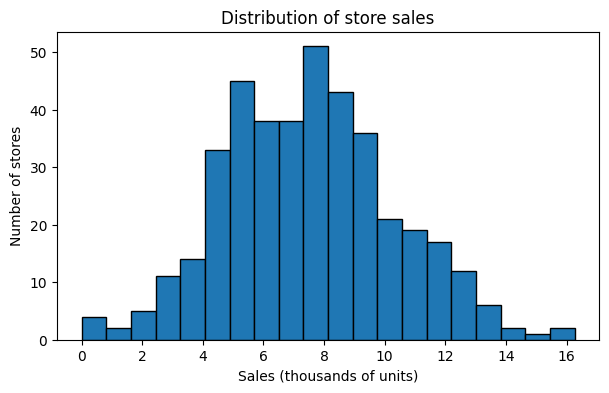

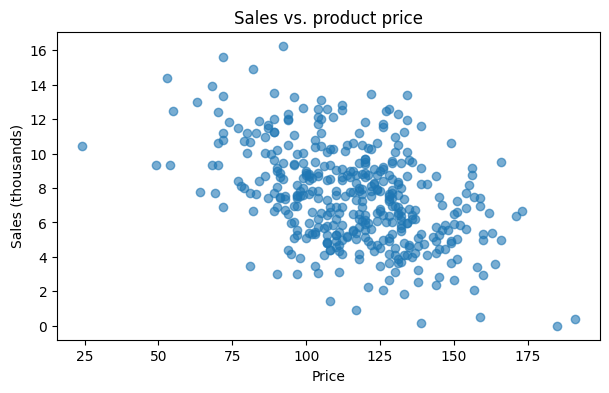

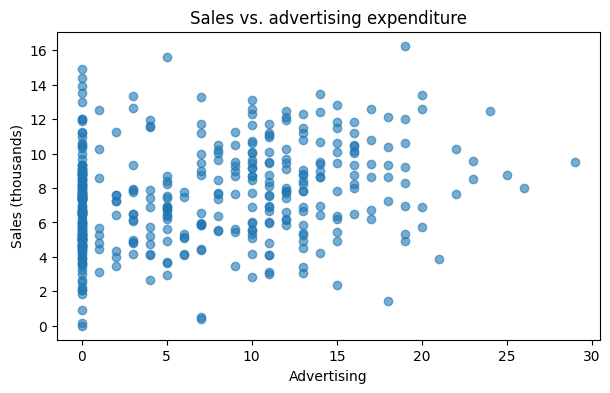

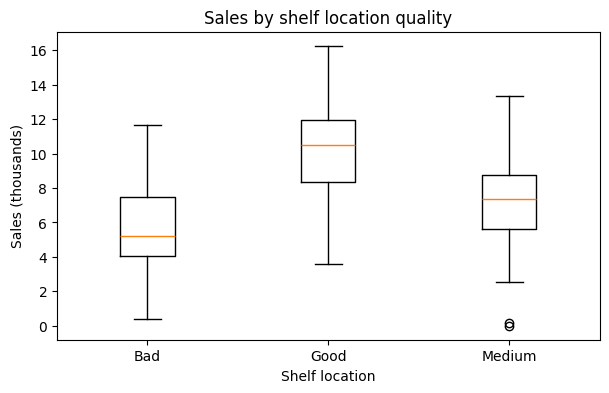

In [18]:
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(df['Sales'], bins=20, edgecolor='black')
ax.set(title='Distribution of store sales', xlabel='Sales (thousands of units)', ylabel='Number of stores')
plt.show()

fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(df['Price'], df['Sales'], alpha=.6)
ax.set(title='Sales vs. product price', xlabel='Price', ylabel='Sales (thousands)')
plt.show()

fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(df['Advertising'], df['Sales'], alpha=.6)
ax.set(title='Sales vs. advertising expenditure', xlabel='Advertising', ylabel='Sales (thousands)')
plt.show()

fig, ax = plt.subplots(figsize=(7,4))
labels = sorted(df['ShelveLoc'].dropna().unique())
ax.boxplot([df.loc[df['ShelveLoc']==v, 'Sales'].dropna() for v in labels], tick_labels=labels)
ax.set(title='Sales by shelf location quality', xlabel='Shelf location', ylabel='Sales (thousands)')
plt.show()


In [19]:
corr = df.select_dtypes(include='number').corr()
print('Numeric correlations with Sales (association, not causation):')
display(corr['Sales'].drop('Sales').sort_values(ascending=False).round(3).to_frame('Pearson r'))

print('Sales by shelf location:')
display(df.groupby('ShelveLoc', observed=True)['Sales'].agg(['count','mean','median','std']).round(2))


Numeric correlations with Sales (association, not causation):


,Pearson r
Advertising,0.270
Income,0.152
CompPrice,0.064
Population,0.050
Education,-0.052
Age,-0.232
Price,-0.445


Sales by shelf location:


,count,mean,median,std
ShelveLoc,,,,
Bad,96,5.52,5.21,2.36
Good,85,10.21,10.50,2.50
Medium,219,7.31,7.38,2.27


**How to interpret the figures:** A histogram shows distribution and unusual values; scatterplots show possible trends and spread; boxplots compare groups. Correlation describes *linear association* and does not establish that changing price or advertising would cause a change in sales.


## 4. Statistical inference
**Question:** Is mean store sales different for urban versus non-urban stores?

- **Population parameter:** Difference in mean sales, μ(urban) − μ(non-urban).
- **Null hypothesis (H₀):** Difference = 0.
- **Alternative hypothesis (H₁):** Difference ≠ 0.
- **Significance level:** α = 0.05.
- **Method:** Welch two-sample t-test with a 95% confidence interval; unlike the pooled t-test, Welch does not require equal group variances.

**Caution:** Stores may not constitute a random representative sample, and store-level observations may not be independent. Interpret the p-value conditionally on these assumptions; the test is not evidence of causation.

In [25]:
urban = df.loc[df['Urban'].astype(str).str.lower()=='yes','Sales'].dropna().to_numpy()
nonurban = df.loc[df['Urban'].astype(str).str.lower()=='no','Sales'].dropna().to_numpy()
assert len(urban)>1 and len(nonurban)>1, 'Expected Urban categories Yes and No.'
test = stats.ttest_ind(urban, nonurban, equal_var=False)
diff = urban.mean() - nonurban.mean()
se = np.sqrt(urban.var(ddof=1)/len(urban) + nonurban.var(ddof=1)/len(nonurban))
v1, v2 = urban.var(ddof=1)/len(urban), nonurban.var(ddof=1)/len(nonurban)
dof = (v1+v2)**2 / (v1**2/(len(urban)-1) + v2**2/(len(nonurban)-1))
critical = stats.t.ppf(0.975, dof)
ci = (diff-critical*se, diff+critical*se)
print(f'Urban n={len(urban)}, mean={urban.mean():.3f}')
print(f'Non-urban n={len(nonurban)}, mean={nonurban.mean():.3f}')
print(f'Mean difference (urban - nonurban): {diff:.3f} thousand units')
print(f'Test Statistics t={test.statistic:.3f}, p={test.pvalue:.4f}')
print(f'95% confidence interval for difference: ({ci[0]:.3f}, {ci[1]:.3f})')
print('Decision at alpha=0.05:', 'Reject H0' if test.pvalue < .05 else 'Do not reject H0')
print('Interpretation:', 'Evidence of a difference in group means.' if test.pvalue < .05 else 'Insufficient evidence of a difference in group means.')


Urban n=282, mean=7.468
Non-urban n=118, mean=7.564
Mean difference (urban - nonurban): -0.095 thousand units
Test Statistics t=-0.309, p=0.7576
95% confidence interval for difference: (-0.704, 0.513)
Decision at alpha=0.05: Do not reject H0
Interpretation: Insufficient evidence of a difference in group means.


## 5. Model development and selection
We compare two models using the **same predictors and the same split**:

- **Multiple linear regression:** an interpretable baseline modeling additive relationships (after dummy encoding categories).
- **Regression tree:** captures thresholds and nonlinear interactions but can overfit if unrestricted.

The test set is held out. We tune tree complexity with **5-fold cross-validation on training data only**.

In [21]:
X = df.drop(columns=['Sales'])
y = df['Sales']
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()
print('Numeric:', numeric_features)
print('Categorical:', categorical_features)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=SEED)
print('Train:', X_train.shape, 'Test:', X_test.shape)

# Compatibility with scikit-learn versions used in Colab.
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocess = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), numeric_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', encoder)]), categorical_features)
])
linear = Pipeline([('prep', preprocess), ('model', LinearRegression())])
tree = Pipeline([('prep', preprocess), ('model', DecisionTreeRegressor(random_state=SEED))])
linear.fit(X_train, y_train)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(tree,
    param_grid={'model__max_depth':[2,3,4,5,6], 'model__min_samples_leaf':[2,5,10,20]},
    scoring='neg_mean_squared_error', cv=cv, n_jobs=-1)
search.fit(X_train, y_train)
best_tree = search.best_estimator_
print('Best tree hyperparameters:', search.best_params_)
print('Best cross-validation RMSE:', round(np.sqrt(-search.best_score_), 3))


Numeric: ['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education']
Categorical: ['ShelveLoc', 'Urban', 'US']
Train: (320, 10) Test: (80, 10)
Best tree hyperparameters: {'model__max_depth': 6, 'model__min_samples_leaf': 10}
Best cross-validation RMSE: 2.011


## 6. Testing, validation, and model comparison
**MAE:** Average absolute error (smaller is better). **RMSE:** Penalizes large errors more (smaller is better). **R²:** Improvement relative to predicting the test-set mean; it can be negative. Compare **held-out test performance**, not just training performance.

In [22]:
models = {'Linear regression': linear, 'Regression tree (tuned)': best_tree}
rows=[]
for name, model in models.items():
    for split, xx, yy in [('Train',X_train,y_train), ('Test',X_test,y_test)]:
        pred = model.predict(xx)
        rows.append({'Model':name,'Split':split,
                     'MAE':mean_absolute_error(yy,pred),
                     'RMSE':np.sqrt(mean_squared_error(yy,pred)),
                     'R2':r2_score(yy,pred)})
results = pd.DataFrame(rows)
display(results.round(3))
test_results = results.loc[results['Split']=='Test'].sort_values('RMSE')
winner = test_results.iloc[0]['Model']
print('Selected model based on lowest held-out test RMSE:', winner)
print('Important: selection based on this test set is illustrative; for rigorous model selection use CV, then evaluate the test set once.')


,Model,Split,MAE,RMSE,R2
0,Linear regression,Train,0.795,0.997,0.866
1,Linear regression,Test,0.843,1.047,0.889
2,Regression tree (tuned),Train,1.177,1.464,0.711
3,Regression tree (tuned),Test,1.761,2.154,0.531


Selected model based on lowest held-out test RMSE: Linear regression
Important: selection based on this test set is illustrative; for rigorous model selection use CV, then evaluate the test set once.


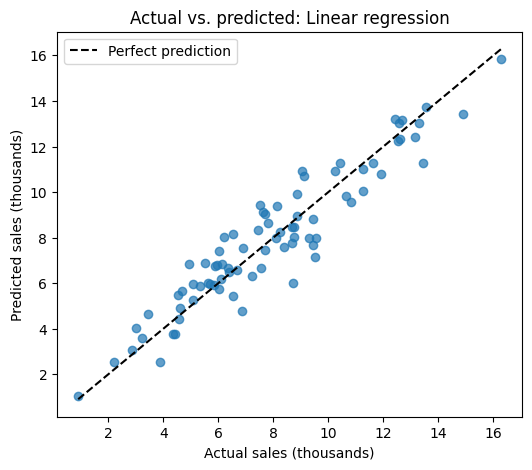

Test RMSE ranking:


,Model,Split,MAE,RMSE,R2
1,Linear regression,Test,0.843,1.047,0.889
3,Regression tree (tuned),Test,1.761,2.154,0.531


In [23]:
fig, ax = plt.subplots(figsize=(6,5))
chosen = models[winner]
pred = chosen.predict(X_test)
ax.scatter(y_test, pred, alpha=.7)
lo = min(y_test.min(), pred.min()); hi = max(y_test.max(), pred.max())
ax.plot([lo,hi],[lo,hi],linestyle='--',color='black',label='Perfect prediction')
ax.set(title=f'Actual vs. predicted: {winner}',xlabel='Actual sales (thousands)',ylabel='Predicted sales (thousands)')
ax.legend()
plt.show()

print('Test RMSE ranking:')
display(test_results.round(3))


**Instructor note:** The previous cell labels the lower-test-RMSE model for demonstration. In a formal project, **choose the model using training cross-validation**, then report test metrics once as an unbiased final check. Avoid repeatedly adjusting models after seeing test results.

**Discuss:** Is the tree's training error substantially smaller than its test error? What would that suggest?

## 7. Results, interpretation, and limitations
We automatically generate a concise interpretation using the computed outputs. Students should still write their own explanation in ordinary language.

In [27]:
print('RESEARCH QUESTION 1 — descriptive')
print('Price–sales Pearson correlation:', round(df[['Price','Sales']].corr().iloc[0,1],3))
print('Advertising–sales Pearson correlation:', round(df[['Advertising','Sales']].corr().iloc[0,1],3))
print('RESEARCH QUESTION 2 — inferential')
print(f'Urban minus non-urban mean sales = {diff:.2f} thousand; 95% CI [{ci[0]:.2f}, {ci[1]:.2f}]; p={test.pvalue:.4f}.')
print('Interpretation:', 'Reject equal means at 5%.' if test.pvalue < .05 else 'Do not reject equal means at 5%.')
print('RESEARCH QUESTION 3 — predictive')
for _, row in test_results.iterrows():
    print(f"{row['Model']}: test MAE={row['MAE']:.2f}, RMSE={row['RMSE']:.2f}, R²={row['R2']:.2f}")
print('Lower test RMSE:', winner)

# Illustrative feature importance: tree impurity-based importance is not a causal effect.
feature_names = best_tree.named_steps['prep'].get_feature_names_out()
importance = pd.Series(best_tree.named_steps['model'].feature_importances_, index=feature_names)
print('Largest tree feature importances (descriptive only):')
display(importance.sort_values(ascending=False).head(8).round(3).to_frame('importance'))


RESEARCH QUESTION 1 — descriptive
Price–sales Pearson correlation: -0.445
Advertising–sales Pearson correlation: 0.27
RESEARCH QUESTION 2 — inferential
Urban minus non-urban mean sales = -0.10 thousand; 95% CI [-0.70, 0.51]; p=0.7576.
Interpretation: Do not reject equal means at 5%.
RESEARCH QUESTION 3 — predictive
Linear regression: test MAE=0.84, RMSE=1.05, R²=0.89
Regression tree (tuned): test MAE=1.76, RMSE=2.15, R²=0.53
Lower test RMSE: Linear regression

Largest tree feature importances (descriptive only):


,importance
num__Price,0.365
cat__ShelveLoc_Good,0.284
num__Age,0.149
num__CompPrice,0.073
num__Advertising,0.047
cat__ShelveLoc_Bad,0.046
cat__ShelveLoc_Medium,0.018
num__Education,0.015


### Sample conclusion template (complete after running)
> We analyzed 400 store records from ISLP Carseats. EDA showed [describe two observed patterns]. A Welch t-test comparing urban and non-urban stores produced a mean difference of [value] thousand units (95% CI [lower, upper], p = [value]); therefore [appropriate interpretation]. We compared multiple linear regression and a tuned regression tree using an 80/20 train/test split. The model with the lower test RMSE was [model], with RMSE [value] thousand units. These results describe association and predictive performance, **not causal effects**.

**Limitations:** Observational store data; unknown sampling/representativeness; possible omitted variables; potential dependence between stores; a single random split may be unstable; future markets may differ. **Improvements:** Repeat cross-validation, collect newer data, investigate residuals and fairness/coverage across store types.


## 8. Reproducibility and code quality
- Dataset: `ISLP.load_data('Carseats')`; documentation linked at top.
- Python libraries: pandas, numpy, scipy, matplotlib, scikit-learn, ISLP.
- Reproducible split and tree: `random_state=42`.
- Run every cell from the top before submitting. Figures and tables have labels.

### Checklist
- [ ] Defined a specific research question and target
- [ ] Checked missing, duplicate, and invalid data; explained decisions
- [ ] Presented descriptive statistics and 3+ relevant plots
- [ ] Reported an appropriate hypothesis test or confidence interval
- [ ] Compared at least two models with justified choices
- [ ] Used a train/test strategy and appropriate metrics
- [ ] Explained results, uncertainty, limitations, and conclusions
- [ ] Made the notebook reproducible and cited the data source

### Optional 5-minute extension
1. Change `test_size=.20` to `.30`: do the model rankings change?
2. Explain why we must rerun all cells after changing the split.
3. Choose one chart and write two sentences that interpret it correctly.

**AI disclosure reminder:** Students should follow the DTSC 4050 course policy and disclose any permitted AI assistance in their own submissions.